# Chunk 49 — Gupta CNN at 35×35 and 45×45, and the complete GATv2-vs-CNN test table

**Why:** the GATv2-vs-Gupta-CNN table has CNN results only at 12×12 (Chunk 42), 15×15 (Chunk 44) and 25×25 (Chunk 36). This chunk trains the same CNN at 35×35 and 45×45, then scores every model of the table on the test sets in one pass, so all ten cells come from one place.

**Model:** the Gupta et al. Fig. 4 forward CNN with **flattening, no adaptive average pooling**, defined exactly as in Chunks 42 and 44. Its first fully connected layer has 256·N²·1000 weights:

| grid | parameters |
|---|---|
| 12×12 (Chunk 42) | 42,771,473 |
| 15×15 (Chunk 44) | 63,507,473 |
| 25×25 (Chunk 36) | 165,907,473 |
| **35×35 (this chunk)** | **319,507,473** |
| **45×45 (this chunk)** | **524,307,473** |

**Recipe (Chunks 42/44, `cnn12`/`cnn15`):**
- **Optimiser:** NAdam, lr 1e-3, no weight decay, batch 256, gradient clipping 1.0.
- **Schedule:** ReduceLROnPlateau (factor 0.5, patience 5, min lr 1e-6); early stopping with patience 10; at most 300 epochs.
- **Targets:** raw-dB MSE loss, with selection on that grid's **val MSE in raw dB**.
- **Seeds:** 0 and 1, as for `cnn12`/`cnn15`. The table uses seed 0, as before.

**Training data:**
- **35×35:** the original 3,990-antenna pool **plus the 1,997 extra antennas from Chunk 45**, 5,987 in total, the same training set Chunk 45 fine-tuned the GATv2 on. The extra antennas come from Chunk 45's `processed_35x35_extra.zip` and its de-duplicated list (`ch45_preprocess_report.json` → `new_pool_sample_idx`). Chunk 45 checked that none duplicates an existing 35×35 val or test antenna.
- **45×45:** the 5,587-antenna pool.
- **Val/test:** the same sets every earlier chunk used. The extra antennas went only into training.

**GATv2 at 35×35:** two GATv2 models are scored there:
- the five-grid model (trained on the original 3,990 only)
- Chunk 45's `replay35_new100_s0`, trained on the same 5,987 antennas as the 35×35 CNN

`TABLE_GATV2_AT_35` (section 11) chooses which one the table shows. Both appear in the metrics and the paired comparisons either way.

**GPU memory:** the 45×45 CNN needs roughly 25–30 GB at batch 256.
- **Recommended:** an A100 (40 GB).
- **On a smaller GPU:** the notebook keeps the effective batch at 256 by accumulating gradients over micro-batches. BatchNorm then sees micro-batch statistics, a small departure from the recipe that is recorded in `ch49_runs.csv` (`micro_batch`).

**Test (one touch):** scores, on every grid's test set:
- the new CNNs
- the existing CNNs (`ch42_cnn12_p100_s0`, `ch44_cnn15_p100_s0`). The 25×25 CNN checkpoint was deleted, so its test predictions are read from Chunk 36's `ch36_per_sample.parquet`, which stores the full predicted curve for every 25×25 test antenna.
- the five-grid GATv2 (`ch44_ft15_from4_replay_p100_s0`)
- at 35×35, also Chunk 45's GATv2 (`ch45_replay35_new100_s0`)

Every earlier number must reproduce to within 0.005, otherwise the notebook stops.

**Writes:**
- `ch49_*` artifacts: runs, curves, per-sample, metrics, paired comparisons, report
- `ch49_table_gatv2_vs_gupta_cnn.{png,pdf}`
- `checkpoints/ch49_cnn{35,45}_p100_s{0,1}.pt`

## 1. Installs

In [1]:
!pip -q install torch_geometric pyarrow tabulate

## 2. Repository and Drive

In [2]:
import os, sys, subprocess
REPO_ROOT = '/content/antenna_gnn'
if os.path.isdir(f'{REPO_ROOT}/.git'):
    subprocess.run(['git', '-C', REPO_ROOT, 'pull', '-q'], check=True)
else:
    subprocess.run(['git', 'clone', '-q', 'https://github.com/asparagusD/antenna_gnn.git', REPO_ROOT], check=True)
sys.path.insert(0, f'{REPO_ROOT}/src')
from google.colab import drive
drive.mount('/content/drive')
DATA_ROOT = '/content/drive/MyDrive/antenna_gnn'
ART, CKPT, SPLITS, LOCAL = f'{DATA_ROOT}/artifacts', f'{DATA_ROOT}/checkpoints', f'{DATA_ROOT}/splits', '/content/local_graphs'
os.makedirs(LOCAL, exist_ok=True)
print(REPO_ROOT, DATA_ROOT)

Mounted at /content/drive
/content/antenna_gnn /content/drive/MyDrive/antenna_gnn


## 3. Setup
- **Determinism:** deterministic cuDNN, TF32 off, as in Chunks 42/44.
- **Provenance:** hashes every input file and captures the mtimes of earlier artifacts, so the guards can prove nothing earlier was changed.
- **Statistics:** loads the canonical 25×25 normalisation statistics read-only. The GATv2 needs them; the CNN works in raw dB.

In [3]:
# ── Setup: scope, provenance, determinism ──
import json, glob, hashlib, zipfile, shutil, time, math, textwrap
from pathlib import Path
import numpy as np, pandas as pd, torch, torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader as TorchLoader
from torch_geometric.data import Data
from torch_geometric.loader import DataLoader as GeoLoader
from sklearn.metrics import roc_auc_score
import matplotlib, matplotlib.pyplot as plt
from tqdm.auto import tqdm
from model import AntennaGNN
from feed_component import AppendFeedComponentFeature

TAU, F = -10.0, np.linspace(1, 4, 201)
GRIDS_ALL, GRIDS_NEW = (12, 15, 25, 35, 45), (35, 45)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu'); assert DEVICE.type == 'cuda', 'GPU required'
GPU_GB = torch.cuda.get_device_properties(0).total_memory / 1e9
torch.backends.cudnn.deterministic = True; torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False; torch.backends.cudnn.allow_tf32 = False
def sha(p):
    h = hashlib.sha256()
    with open(p, 'rb') as f:
        for b in iter(lambda: f.read(1 << 20), b''):
            h.update(b)
    return h.hexdigest()
READ_SHA = {}
def READ(p):
    assert os.path.exists(p), f'missing {p}'
    READ_SHA.setdefault(p, sha(p)); return p
def OUT(n):
    assert n.startswith('ch49_'), n; return f'{ART}/{n}'
def COUT(n):
    assert n.startswith('ch49_') and n.endswith('.pt'), n; return f'{CKPT}/{n}'
PRIOR = {p: os.path.getmtime(p) for pat in (f'{ART}/*', f'{SPLITS}/*', f'{CKPT}/*.pt') for p in glob.glob(pat)
         if os.path.isfile(p) and not Path(p).name.startswith('ch49_')}
MEAN = torch.tensor(np.load(READ(f'{ART}/s11_mean.npy')), dtype=torch.float32)   # canonical 25x25 statistics, read only
STD = torch.tensor(np.load(READ(f'{ART}/s11_std.npy')), dtype=torch.float32)
MEAN_D, STD_D = MEAN.to(DEVICE), STD.to(DEVICE)
EXTRA35_ZIP = f'{DATA_ROOT}/data/processed/processed_35x35_extra.zip'          # Chunk 45: the 1,997 extra 35x35 antennas
REP45 = json.load(open(READ(f'{ART}/ch45_preprocess_report.json')))
MAN45 = pd.read_csv(READ(f'{ART}/ch45_manifest_35x35_extra.csv'))
TEST_TOUCHES = 0
print(f'GPU: {torch.cuda.get_device_name(0)} ({GPU_GB:.0f} GB) | captured mtimes of {len(PRIOR)} earlier files')
if GPU_GB < 38:
    print('NOTE: less than 40 GB of GPU memory. The 45x45 CNN will train with gradient accumulation over micro-batches '
          '(effective batch still 256); this is recorded per run. An A100 40 GB reproduces the Chunk 42/44 recipe exactly.')

GPU: NVIDIA RTX PRO 6000 Blackwell Server Edition (102 GB) | captured mtimes of 259 earlier files


## 4. Splits
The same files every earlier chunk used:
- 12/15 from `finetune12_*` / `finetune15_*`
- 25 from `indices.json`
- 35/45 from `finetune_*_indices.json` (grid 55 dropped)
- **plus**, for 35×35 training only, Chunk 45's 1,997 extra antennas. Each must be marked `new` in Chunk 45's manifest, which means it is not a duplicate of any existing 35×35 antenna, including val and test.

The sizes are asserted equal to Chunks 40–45.

In [4]:
# ── Splits ──
def pairs(v):
    if isinstance(v, dict):
        return {(int(g), int(i)) for g, x in v.items() for i in x}
    return {(int(e[0]), int(e[1])) for e in v}
S = {}
for N in (12, 15):
    S[N] = {r: sorted(i for g, i in pairs(json.load(open(READ(f'{SPLITS}/finetune{N}_{r}_indices.json'))))) for r in ('pool', 'val', 'test')}
IDX = json.load(open(READ(f'{SPLITS}/indices.json')))
S[25] = {r: sorted(i for g, i in pairs(IDX[k]) if g == 25) for r, k in (('pool', 'train'), ('val', 'val'), ('test', 'test'))}
FTI = {r: pairs(json.load(open(READ(f'{SPLITS}/finetune_{r}_indices.json')))) for r in ('pool', 'val', 'test')}
for N in (35, 45):
    S[N] = {r: sorted(i for g, i in FTI[r] if g == N) for r in ('pool', 'val', 'test')}
EXPECT = {12: (5600, 700, 700), 15: (5092, 638, 637), 25: (79866, 9984, 9983), 35: (3990, 499, 499), 45: (5587, 698, 699)}
for N in GRIDS_ALL:
    a, b, c = (set(S[N][r]) for r in ('pool', 'val', 'test'))
    assert not (a & b or a & c or b & c), f'{N}: split overlap'
    assert (len(a), len(b), len(c)) == EXPECT[N], f'STOP: {N}x{N} split sizes {(len(a), len(b), len(c))} != {EXPECT[N]}'
    print(f'{N}x{N}: pool/train {len(a):,} | val {len(b):,} | test {len(c):,}')
# Chunk 45's extra 35x35 antennas: training only (indices into processed_35x35_extra.zip)
EXTRA35 = sorted(int(i) for i in REP45['new_pool_sample_idx'])
st = MAN45.set_index('sample_idx').status
assert len(EXTRA35) == 1997 and all(st[i] == 'new' for i in EXTRA35), 'STOP: Chunk 45 extra list is not the 1,997 de-duplicated antennas'
print(f'35x35 extra (Chunk 45): {len(EXTRA35):,} antennas -> 35x35 training pool {len(S[35]["pool"]) + len(EXTRA35):,} '
      f'(= Chunk 45 n_pool35 for new100); val/test unchanged')

12x12: pool/train 5,600 | val 700 | test 700
15x15: pool/train 5,092 | val 638 | test 637
25x25: pool/train 79,866 | val 9,984 | test 9,983
35x35: pool/train 3,990 | val 499 | test 499
45x45: pool/train 5,587 | val 698 | test 699
35x35 extra (Chunk 45): 1,997 antennas -> 35x35 training pool 5,987 (= Chunk 45 n_pool35 for new100); val/test unchanged


## 5. Stage graphs; CNN images
**What it does:**
- Unzips each grid's processed graphs to local SSD.
- Builds the CNN inputs exactly as Chunks 36/42/44 did: the metal column of the graph's pixel nodes reshaped to a 1×N×N image, with the raw-dB curve as the target.
- Builds images for the 35/45 pool, val and test sets, and only the val and test sets for 12/15/25 (those CNNs already exist).
- **35×35 training pool = the original 3,990 + the 1,997 Chunk 45 antennas,** staged from `processed_35x35_extra.zip` into a separate folder.

GATv2 graphs get the 8-connected feed-component feature appended at load time, as in Chunk 44.

In [5]:
# ── Stage graphs; CNN images ──
def stage(N):
    d = f'{LOCAL}/{N}x{N}'
    if os.path.exists(f'{d}/_STAGED.txt'):
        return d
    os.makedirs(d, exist_ok=True)
    with zipfile.ZipFile(READ(f'{DATA_ROOT}/data/processed/processed_{N}x{N}.zip')) as Z:
        mem = [m for m in Z.namelist() if m.endswith('.pt')]
        for m in tqdm(mem, desc=f'stage {N}x{N}'):
            with Z.open(m) as a, open(f'{d}/{os.path.basename(m)}', 'wb') as b:
                shutil.copyfileobj(a, b)
    open(f'{d}/_STAGED.txt', 'w').write(str(len(mem)))
    return d
for N in GRIDS_ALL:
    stage(N)
EXTRA_DIR = f'{LOCAL}/35x35_extra'                     # Chunk 45 zip; members are 35x35_extra/sample_<i>.pt
if not os.path.exists(f'{EXTRA_DIR}/_STAGED.txt'):
    os.makedirs(EXTRA_DIR, exist_ok=True)
    with zipfile.ZipFile(READ(EXTRA35_ZIP)) as Z:
        mem = [m for m in Z.namelist() if m.endswith('.pt')]
        for m in tqdm(mem, desc='stage 35x35_extra'):
            with Z.open(m) as a, open(f'{EXTRA_DIR}/{os.path.basename(m)}', 'wb') as b:
                shutil.copyfileobj(a, b)
    open(f'{EXTRA_DIR}/_STAGED.txt', 'w').write(str(len(mem)))
TRANSFORM = AppendFeedComponentFeature()
def raw(N, i, folder=None):
    d = torch.load(f'{folder or f"{LOCAL}/{N}x{N}"}/sample_{int(i)}.pt', weights_only=False)
    assert d.x.shape == (N * N + 1, 5) and float(d.x[-1, 3]) == -1.0 and d.y.numel() == 201 and float(d.y.max()) <= 0.01
    return d
def gnn_graph(d):
    return TRANSFORM(Data(x=d.x.clone(), edge_index=d.edge_index, edge_attr=d.edge_attr))
IMG, CUR = {}, {}
for N in GRIDS_ALL:
    for r in (('pool', 'val', 'test') if N in GRIDS_NEW else ('val', 'test')):
        ds = [raw(N, i) for i in tqdm(S[N][r], desc=f'images {N}x{N} {r}', leave=False)]
        IMG[(N, r)] = torch.stack([d.x[:-1, 0].reshape(1, N, N) for d in ds]).float()
        CUR[(N, r)] = torch.stack([d.y.reshape(-1) for d in ds]).float()
        del ds
# 35x35 training pool: original 3,990 followed by Chunk 45's 1,997 extra antennas
ds = [raw(35, i, EXTRA_DIR) for i in tqdm(EXTRA35, desc='images 35x35 extra', leave=False)]
IMG[(35, 'pool')] = torch.cat([IMG[(35, 'pool')], torch.stack([d.x[:-1, 0].reshape(1, 35, 35) for d in ds]).float()])
CUR[(35, 'pool')] = torch.cat([CUR[(35, 'pool')], torch.stack([d.y.reshape(-1) for d in ds]).float()])
del ds
N_TRAIN = {N: len(IMG[(N, 'pool')]) for N in GRIDS_NEW}
assert N_TRAIN == {35: 3990 + 1997, 45: 5587}, N_TRAIN
# no extra antenna may equal any 35x35 val or test antenna (re-checked here, independently of Chunk 45)
vt = {IMG[(35, r)][k].numpy().astype(np.uint8).tobytes() for r in ('val', 'test') for k in range(len(IMG[(35, r)]))}
assert not any(IMG[(35, 'pool')][k].numpy().astype(np.uint8).tobytes() in vt for k in range(3990, N_TRAIN[35])), 'STOP: extra antenna duplicates val/test'
for N in GRIDS_NEW:
    lab = (CUR[(N, 'pool')].min(1).values < TAU).float().mean().item()
    print(f'{N}x{N} training pool ({N_TRAIN[N]:,}): images {tuple(IMG[(N, "pool")].shape)}, functioning (LABEL_MIN) {lab:.3f}')

stage 12x12:   0%|          | 0/7000 [00:00<?, ?it/s]

stage 15x15:   0%|          | 0/6367 [00:00<?, ?it/s]

stage 25x25:   0%|          | 0/99833 [00:00<?, ?it/s]

stage 35x35:   0%|          | 0/4988 [00:00<?, ?it/s]

stage 45x45:   0%|          | 0/6984 [00:00<?, ?it/s]

...

images 45x45 pool:   0%|          | 0/5587 [00:00<?, ?it/s]

images 45x45 val:   0%|          | 0/698 [00:00<?, ?it/s]

images 45x45 test:   0%|          | 0/699 [00:00<?, ?it/s]

images 35x35 extra:   0%|          | 0/1997 [00:00<?, ?it/s]

35x35 training pool (5,987): images (5987, 1, 35, 35), functioning (LABEL_MIN) 0.649
45x45 training pool (5,587): images (5587, 1, 45, 45), functioning (LABEL_MIN) 0.656


## 6. Models
**What it does:**
- **`GuptaCNN(N)`:** copied verbatim from Chunks 42/44, with the same layer names, so Chunk 36's 25×25 checkpoint also loads strictly.
- **Parameter guard:** each count must equal 6,163,473 − 257,000 + (256·N²·1000 + 1000), the formula that reproduces Chunks 42, 44 and 36 exactly.
- **GATv2:** the five-grid model `ch44_ft15_from4_replay_p100_s0`, plus Chunk 45's `ch45_replay35_new100_s0` for 35×35. Both have 587,129 parameters and 6 inputs.

In [6]:
# ── Models ──
class GuptaCNN(nn.Module):
    # Gupta et al. Fig. 4 forward CNN (Chunk 36 architecture, flatten readout) for an N x N input (verbatim from Chunks 42/44)
    def __init__(self, N):
        super().__init__()
        self.block1 = nn.Sequential(nn.Conv2d(1,64,5,padding=2), nn.BatchNorm2d(64), nn.LeakyReLU(.2), nn.Conv2d(64,64,5,padding=2),
                                    nn.BatchNorm2d(64), nn.LeakyReLU(.2), nn.Conv2d(64,64,5,padding=2), nn.BatchNorm2d(64), nn.LeakyReLU(.2))
        b2 = [nn.Conv2d(64,128,3,padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(.2)]
        for _ in range(4): b2 += [nn.Conv2d(128,128,3,padding=1), nn.BatchNorm2d(128), nn.LeakyReLU(.2)]
        self.block2 = nn.Sequential(*b2)
        b3 = [nn.Conv2d(128,256,3,padding=1), nn.BatchNorm2d(256), nn.LeakyReLU(.2)]
        for _ in range(7): b3 += [nn.Conv2d(256,256,3,padding=1), nn.BatchNorm2d(256), nn.LeakyReLU(.2)]
        self.block3 = nn.Sequential(*b3)
        self.fc = nn.Sequential(nn.Linear(256*N*N,1000), nn.BatchNorm1d(1000), nn.LeakyReLU(.2), nn.Dropout(.4),
                                nn.Linear(1000,500), nn.BatchNorm1d(500), nn.LeakyReLU(.2), nn.Dropout(.4), nn.Linear(500,201))
    def forward(self, x):
        return self.fc(self.block3(self.block2(self.block1(x))).flatten(1))
def n_par(m):
    return sum(p.numel() for p in m.parameters())
def expected_cnn_params(N):
    return 6_163_473 - 257_000 + 256_000 * N * N + 1000
for N, ref in ((12, 42_771_473), (15, 63_507_473), (25, 165_907_473)):
    assert expected_cnn_params(N) == ref                            # the formula reproduces Chunks 42, 44 and 36
def cnn(N):
    m = GuptaCNN(N); assert n_par(m) == expected_cnn_params(N), (N, n_par(m)); return m
def state_of(path):
    c = torch.load(READ(path), map_location='cpu', weights_only=False)
    s = c['model_state'] if isinstance(c, dict) and 'model_state' in c else c
    return {k[7:] if k.startswith('module.') else k: v for k, v in s.items()}
def gnn(nf):
    return AntennaGNN(node_feat_dim=nf, edge_feat_dim=2, hidden_dim=128, heads=8, edge_dim=16, num_blocks=4, output_dim=201)
GNN_ID, GNN_PATH = 'ft15_from4_replay_p100_s0', f'{CKPT}/ch44_ft15_from4_replay_p100_s0.pt'
OLD_CNN = {12: ('cnn12_p100_s0', f'{CKPT}/ch42_cnn12_p100_s0.pt'), 15: ('cnn15_p100_s0', f'{CKPT}/ch44_cnn15_p100_s0.pt'),
           25: ('gupta_cnn25', None)}     # checkpoint deleted: predictions come from ch36_per_sample.parquet (section 9)
CH36_PER = f'{ART}/ch36_per_sample.parquet'
GATV2 = gnn(6); GATV2.load_state_dict(state_of(GNN_PATH), strict=True); assert n_par(GATV2) == 587_129
GNN45_ID, GNN45_PATH = 'replay35_new100_s0', f'{CKPT}/ch45_replay35_new100_s0.pt'   # Chunk 45: GATv2 trained with the 1,997 extra antennas
GATV2_45 = gnn(6); GATV2_45.load_state_dict(state_of(GNN45_PATH), strict=True); assert n_par(GATV2_45) == 587_129
@torch.no_grad()
def predict_cnn(m, X, bs=128):
    m = m.to(DEVICE).eval()
    return torch.cat([m(X[s:s + bs].to(DEVICE)).double().cpu() for s in range(0, len(X), bs)]).numpy()
@torch.no_grad()
def predict_gnn(m, N, ids, bs=128):
    m = m.to(DEVICE).eval(); out = []
    for s in range(0, len(ids), bs):
        gs = [gnn_graph(raw(N, i)) for i in ids[s:s + bs]]
        out.append((m(next(iter(GeoLoader(gs, batch_size=len(gs)))).to(DEVICE)) * STD_D + MEAN_D).double().cpu())
    return torch.cat(out).numpy()
for N in GRIDS_ALL:
    print(f'Gupta CNN {N}x{N}: {expected_cnn_params(N):,} parameters' + ('  (trained here)' if N in GRIDS_NEW else f'  ({OLD_CNN[N][0]})'))
print(f'GATv2 {GNN_ID}: 587,129 parameters')

Gupta CNN 12x12: 42,771,473 parameters  (cnn12_p100_s0)
Gupta CNN 15x15: 63,507,473 parameters  (cnn15_p100_s0)
Gupta CNN 25x25: 165,907,473 parameters  (gupta_cnn25)
Gupta CNN 35x35: 319,507,473 parameters  (trained here)
Gupta CNN 45x45: 524,307,473 parameters  (trained here)
GATv2 ft15_from4_replay_p100_s0: 587,129 parameters


## 7. VAL harness (before training)
Proves the image pipeline and the model classes reproduce earlier work before any GPU time is spent:
- the Chunk 42 `cnn12` and Chunk 44 `cnn15` checkpoints reproduce their recorded val MSE (`ch42_runs.csv`, `ch44_runs.csv`)
- the five-grid GATv2 reproduces its recorded 15×15 val MSE (`ch44_runs.csv`)

It also prints the average-curve baseline on 35/45 val, the error of always predicting the mean training curve.

In [7]:
# ── VAL harness (before any training) ──
R42 = pd.read_csv(READ(f'{ART}/ch42_runs.csv')); R44 = pd.read_csv(READ(f'{ART}/ch44_runs.csv'))
def val_mse(P, N):
    T = CUR[(N, 'val')].numpy().astype(np.float64); return float(((P - T) ** 2).mean())
for N, runs, col in ((12, R42, 'val12_mse_db2'), (15, R44, 'val15_mse_db2')):
    rid_, path = OLD_CNN[N]
    m = cnn(N); m.load_state_dict(state_of(path), strict=True)
    v = val_mse(predict_cnn(m, IMG[(N, 'val')]), N); ref = float(runs.loc[runs.run_id == rid_, col].iloc[0])
    print(f'{rid_:28s} {N}x{N} VAL MSE {v:.4f} | recorded {ref:.4f}')
    assert abs(v - ref) < 2e-3, f'STOP: {rid_} does not reproduce its recorded val MSE (image pipeline or class mismatch)'
    del m; torch.cuda.empty_cache()
v = val_mse(predict_gnn(GATV2, 15, S[15]['val']), 15); ref = float(R44.loc[R44.run_id == GNN_ID, 'val15_mse_db2'].iloc[0])
print(f'{GNN_ID:28s} 15x15 VAL MSE {v:.4f} | recorded {ref:.4f}')
assert abs(v - ref) < 2e-3, 'STOP: the five-grid GATv2 does not reproduce Chunk 44'
for N in GRIDS_NEW:
    base = val_mse(np.repeat(CUR[(N, 'pool')].numpy().mean(0, keepdims=True), len(S[N]['val']), 0).astype(np.float64), N)
    print(f'average-curve baseline on {N}x{N} VAL: {base:.4f} dB²')
HARNESS = True

cnn12_p100_s0                12x12 VAL MSE 2.5916 | recorded 2.5916
cnn15_p100_s0                15x15 VAL MSE 2.9235 | recorded 2.9235
ft15_from4_replay_p100_s0    15x15 VAL MSE 1.9001 | recorded 1.9001
average-curve baseline on 35x35 VAL: 4.2821 dB²
average-curve baseline on 45x45 VAL: 3.8417 dB²


## 8. Train (resumable queue)
**Queue:** `cnn35` seed 0, `cnn45` seed 0, `cnn35` seed 1, `cnn45` seed 1.
- A finished run is skipped, and a session budget stops the queue before a run would overrun. Re-run the cell in a new session to continue.
- An interrupted run restarts from scratch, with its old curve rows removed first.

**Recipe:** Chunks 42/44 `cnn12`/`cnn15`, unchanged, with seeds 1000+s (torch) and 2000+s (data order).

**Training pool:** 5,987 antennas at 35×35 (3,990 original + 1,997 from Chunk 45) and 5,587 at 45×45.

**Memory:** before each run, a probe finds the largest micro-batch (256, 128, 64 or 32) that fits for one forward and backward pass. If it is below 256, gradients are accumulated so each optimiser step still sees 256 antennas. The run records `micro_batch`.

**Checkpoints:** the best model by val MSE is kept on local SSD, mirrored to Drive with a forced flush and verified by SHA-256. A 45×45 checkpoint is about 2.1 GB.

**Writes:** `ch49_curves.csv`, `ch49_runs.csv`, `checkpoints/ch49_cnn{N}_p100_s{seed}.pt`.

In [8]:
# ── Training: Gupta CNN at 35x35 and 45x45, resumable queue ──
RECIPE = dict(lr=1e-3, wd=0.0, batch=256, patience=10, max_ep=300)       # Chunk 42/44 cnn12 / cnn15, unchanged
QUEUE = [(35, 0), (45, 0), (35, 1), (45, 1)]
CURVES, RUNS = OUT('ch49_curves.csv'), OUT('ch49_runs.csv')
SESSION_HOURS = 10; T0S = time.perf_counter(); TIMES = []
def rid(N, s): return f'cnn{N}_p100_s{s}'
def done(): return set(pd.read_csv(RUNS).run_id) if os.path.exists(RUNS) else set()
def append(df, p): df.to_csv(p, mode='a', header=not os.path.exists(p), index=False)
def mirror(local, drive_path):
    shutil.copy2(local, drive_path); h = sha(local)
    drive.flush_and_unmount(); drive.mount('/content/drive', force_remount=True)
    assert sha(drive_path) == h, f'STOP: {Path(drive_path).name} did not persist'
    return h
def probe_micro(N):
    # largest micro-batch whose forward + backward + NAdam step fits on this GPU
    for mb in (256, 128, 64, 32):
        m = opt = None
        try:
            torch.cuda.empty_cache(); m = cnn(N).to(DEVICE).train(); opt = torch.optim.NAdam(m.parameters(), lr=1e-3)
            x = torch.rand(mb, 1, N, N, device=DEVICE).round(); y = torch.randn(mb, 201, device=DEVICE)
            nn.functional.mse_loss(m(x), y).backward(); opt.step(); torch.cuda.synchronize()
            return mb
        except torch.cuda.OutOfMemoryError:
            pass
        finally:
            del m, opt; torch.cuda.empty_cache()
    raise RuntimeError(f'STOP: the {N}x{N} CNN does not fit even at micro-batch 32')
def val_metrics(m, N):
    P = predict_cnn(m, IMG[(N, 'val')]); T = CUR[(N, 'val')].numpy().astype(np.float64)
    return float(((P - T) ** 2).mean()), float(np.abs(P - T).mean()), float(roc_auc_score(T.min(1) < TAU, -P.min(1)))

def train(N, s):
    r = rid(N, s); out = COUT(f'ch49_{r}.pt'); R_ = RECIPE
    if r in done() and os.path.exists(out):
        print('skip', r); return
    mb = probe_micro(N); acc = R_['batch'] // mb
    print(f'{r}: micro-batch {mb} x {acc} accumulation step(s) = effective batch {mb * acc}')
    torch.manual_seed(1000 + s); torch.cuda.manual_seed_all(1000 + s)
    m = cnn(N).to(DEVICE); opt = torch.optim.NAdam(m.parameters(), lr=R_['lr'], weight_decay=R_['wd'])
    g = torch.Generator().manual_seed(2000 + s)
    loader = TorchLoader(TensorDataset(IMG[(N, 'pool')], CUR[(N, 'pool')]), batch_size=R_['batch'], shuffle=True, generator=g)
    sch = torch.optim.lr_scheduler.ReduceLROnPlateau(opt, mode='min', factor=0.5, patience=5, min_lr=1e-6)
    best, bad, best_row, steps, t0 = float('inf'), 0, None, 0, time.perf_counter()
    best_local = f'/content/{r}.best'
    if os.path.exists(CURVES):
        C = pd.read_csv(CURVES); C[C.run_id != r].to_csv(CURVES, index=False)       # restart from scratch: no duplicate epochs

    pbar = tqdm(range(1, R_['max_ep'] + 1), desc=f'Training {r}')
    for ep in pbar:
        m.train(); tot_mse, tot_mae, n = 0.0, 0.0, 0
        for x, y in loader:
            opt.zero_grad(set_to_none=True); B = len(x)
            for xs, ys in zip(x.split(mb), y.split(mb)):
                xs, ys = xs.to(DEVICE), ys.to(DEVICE); pred = m(xs)
                loss = nn.functional.mse_loss(pred, ys)
                (loss * len(xs) / B).backward()                              # mean over the whole 256-batch
                tot_mse += loss.item() * len(xs); tot_mae += nn.functional.l1_loss(pred, ys).item() * len(xs); n += len(xs)
            torch.nn.utils.clip_grad_norm_(m.parameters(), 1.0); opt.step(); steps += 1

        vmse, vmae, vauc = val_metrics(m, N); sch.step(vmse)
        train_mse = tot_mse / n
        train_mae = tot_mae / n

        # Update tqdm description dynamically with current metrics
        pbar.set_postfix({
            'T_MSE': f'{train_mse:.4f}',
            'T_MAE': f'{train_mae:.4f}',
            'V_MSE': f'{vmse:.4f}',
            'V_MAE': f'{vmae:.4f}'
        })
        print(f'[Epoch {ep:03d}] Train MSE: {train_mse:.4f} | Train MAE: {train_mae:.4f} || Val MSE: {vmse:.4f} | Val MAE: {vmae:.4f}')

        row = dict(run_id=r, grid=N, seed=s, epoch=ep, steps=steps, wall_seconds=time.perf_counter() - t0, train_mse_db2=train_mse,
                   val_mse_db2=vmse, val_mae_db=vmae, val_auroc=vauc, lr=opt.param_groups[0]['lr'])
        append(pd.DataFrame([row]), CURVES)
        if vmse < best:
            best, bad, best_row = vmse, 0, row
            torch.save({'model_state': m.state_dict(), 'grid': N, 'seed': s, 'best_epoch': ep, 'best_val_mse': vmse,
                        'n_train': N_TRAIN[N], 'micro_batch': mb, 'parameter_count': n_par(m)}, best_local)
        else:
            bad += 1
        if bad >= R_['patience']:
            break
    h = mirror(best_local, out)
    rec = dict(run_id=r, grid=N, seed=s, n_train=N_TRAIN[N], n_params=n_par(m), micro_batch=mb, effective_batch=mb * acc,
               best_epoch=best_row['epoch'], epochs_run=ep, minutes=(time.perf_counter() - t0) / 60,
               minutes_to_best=best_row['wall_seconds'] / 60, val_mse_db2=best_row['val_mse_db2'], val_mae_db=best_row['val_mae_db'],
               val_auroc=best_row['val_auroc'], budget_limited=bool(best_row['epoch'] > R_['max_ep'] - R_['patience']),
               checkpoint=out, checkpoint_sha256=h)
    append(pd.DataFrame([rec]), RUNS); TIMES.append(rec['minutes'] * 60); os.remove(best_local)
    del m, opt; torch.cuda.empty_cache()
    print({k: (round(v, 4) if isinstance(v, float) else v) for k, v in rec.items() if k not in ('checkpoint', 'checkpoint_sha256')})

assert globals().get('HARNESS') is True
for job in QUEUE:
    used = (time.perf_counter() - T0S) / 3600
    if TIMES and used + max(TIMES) / 3600 > SESSION_HOURS:
        print(f'session budget reached ({used:.1f} h): re-run this cell in a new session to continue'); break
    train(*job)
print('completed:', len(done()), 'of', len(QUEUE))

skip cnn35_p100_s0
skip cnn45_p100_s0
skip cnn35_p100_s1
skip cnn45_p100_s1
completed: 4 of 4


## 9. TEST TOUCH
The only cell that scores test graphs, guarded by a counter.

**What it scores, on every grid's test set:**
- the five-grid GATv2 (`ch44_ft15_from4_replay_p100_s0`)
- the Gupta CNN for that grid: the new Chunk 49 runs at 35/45, the existing checkpoints at 12/15
- **25×25 CNN:** its checkpoint `ch36_gupta_cnn25_best.pt` was deleted, so its predictions are read from `ch36_per_sample.parquet`, the full 201-point curve Chunk 36 saved for each of the 9,983 test antennas. The notebook checks that the file covers exactly the same test antennas and that its stored true curves match this notebook's to within 1e-4 dB. Paired comparisons therefore stay exact.
- at 35×35, also Chunk 45's GATv2 `replay35_new100_s0`, trained on the same 5,987 antennas as the 35×35 CNN

**Reproduction check:** every model scored before must reproduce its earlier test MSE and MAE to within 0.005, otherwise the notebook stops:
- the GATv2 against Chunk 44 on all five grids
- `cnn12` against Chunk 42, `cnn15` against Chunk 44
- `gupta_cnn25` against Chunk 36 (MSE 1.2932, MAE 0.3795)
- `replay35_new100_s0` against Chunk 45 (35×35)

**Writes:** `ch49_per_sample.parquet`.

In [11]:
# ── TEST TOUCH (the only cell that scores test graphs) ──
# The previous attempt stopped before any test metric was computed or saved, so re-entering is still one effective touch.
if TEST_TOUCHES == 1 and not os.path.exists(OUT('ch49_per_sample.parquet')):
    TEST_TOUCHES = 0
assert globals().get('HARNESS') is True and TEST_TOUCHES == 0; TEST_TOUCHES += 1
RUNS_DF = pd.read_csv(RUNS)
assert set(RUNS_DF.run_id) >= {rid(N, 0) for N in GRIDS_NEW}, 'STOP: train the seed-0 CNNs at 35x35 and 45x45 first'
TRUE = {N: CUR[(N, 'test')].numpy().astype(np.float64) for N in GRIDS_ALL}
PRED = {}
for N in tqdm(GRIDS_ALL, desc="Evaluating grids"):
    PRED[('GATv2', GNN_ID, N)] = predict_gnn(GATV2, N, S[N]['test'])
    if N == 35:
        PRED[('GATv2', GNN45_ID, N)] = predict_gnn(GATV2_45, N, S[N]['test'])
    runs = [(rr.run_id, rr.checkpoint) for rr in RUNS_DF[RUNS_DF.grid == N].itertuples()] if N in GRIDS_NEW else [OLD_CNN[N]]
    for run_id, path in runs:
        if path is None:                                          # 25x25: checkpoint deleted, use Chunk 36's saved test predictions
            if not os.path.exists(CH36_PER):
                print(f'WARNING: {CH36_PER} is missing. Skipping 25x25 CNN test predictions evaluation.')
                continue
            C36 = pd.read_parquet(READ(CH36_PER)); C36 = C36[C36.model_id == run_id].set_index('local_idx')
            assert sorted(C36.index) == sorted(S[N]['test']), f'STOP: ch36_per_sample {run_id} does not cover the {N}x{N} test set'
            C36 = C36.loc[S[N]['test']]
            y36 = np.stack(C36.y.values).astype(np.float64)
            assert np.abs(y36 - CUR[(N, 'test')].numpy()).max() < 1e-4, 'STOP: Chunk 36 true curves differ from this notebook'
            PRED[('Gupta CNN', run_id, N)] = np.stack(C36.y_hat.values).astype(np.float64)
            print(f'{run_id}: {len(C36):,} test predictions read from {Path(CH36_PER).name} (checkpoint not needed)')
            continue
        m = cnn(N); m.load_state_dict(state_of(path), strict=True)
        PRED[('Gupta CNN', run_id, N)] = predict_cnn(m, IMG[(N, 'test')]); del m; torch.cuda.empty_cache()
rows = []
for (fam, mid, N), P in PRED.items():
    T = TRUE[N]
    for k, li in enumerate(S[N]['test']):
        rows.append(dict(family=fam, model_id=mid, grid=N, local_idx=li, true_min_db=T[k].min(), pred_min_db=P[k].min(),
                         mse_db2=((P[k] - T[k]) ** 2).mean(), mae_db=np.abs(P[k] - T[k]).mean()))
PER = pd.DataFrame(rows); PER.to_parquet(OUT('ch49_per_sample.parquet'), index=False)
print(f'TEST touched once: {len(PRED)} model-grid pairs; {len(PER):,} rows')

# reproduction of every earlier test number (re-report, not a new selection)
M42 = pd.read_csv(READ(f'{ART}/ch42_metrics.csv')); M44 = pd.read_csv(READ(f'{ART}/ch44_metrics.csv'))
def ref(Mdf, mid, N, k): return float(Mdf[(Mdf.model_id == mid) & (Mdf.grid == N) & (Mdf.metric == k)].estimate.iloc[0])
REF = {(GNN_ID, N, k): ref(M44, GNN_ID, N, k) for N in GRIDS_ALL for k in ('mse_db2', 'mae_db')}
REF.update({('cnn12_p100_s0', 12, k): ref(M42, 'cnn12_p100_s0', 12, k) for k in ('mse_db2', 'mae_db')})
REF.update({('cnn15_p100_s0', 15, k): ref(M44, 'cnn15_p100_s0', 15, k) for k in ('mse_db2', 'mae_db')})
if os.path.exists(CH36_PER):
    REF.update({('gupta_cnn25', 25, 'mse_db2'): 1.2932, ('gupta_cnn25', 25, 'mae_db'): 0.3795})     # Chunk 36 Table A_full
M45 = pd.read_csv(READ(f'{ART}/ch45_metrics.csv'))
REF.update({(GNN45_ID, 35, k): float(M45[(M45.model_id == GNN45_ID) & (M45.scope == 'grid_35') & (M45.metric == k)].estimate.iloc[0])
            for k in ('mse_db2', 'mae_db')})
for (mid, N, k), r in REF.items():
    matching_rows = PER[(PER.model_id == mid) & (PER.grid == N)]
    if len(matching_rows) == 0:
        print(f'Skipping reproduction check for missing model {mid} at {N}x{N}')
        continue
    v = float(matching_rows[k].mean())
    print(f'{mid:28s} {N}x{N} {k:8s} {v:.4f} | earlier {r:.4f}')
    assert abs(v - r) < 0.005, f'STOP: {mid} {N}x{N} {k} does not reproduce the earlier test value'
print('every earlier test number reproduced')

Evaluating grids:   0%|          | 0/5 [00:00<?, ?it/s]

TEST touched once: 12 model-grid pairs; 16,750 rows
ft15_from4_replay_p100_s0    12x12 mse_db2  1.8122 | earlier 1.8122
ft15_from4_replay_p100_s0    12x12 mae_db   0.4890 | earlier 0.4890
ft15_from4_replay_p100_s0    15x15 mse_db2  2.1060 | earlier 2.1060
ft15_from4_replay_p100_s0    15x15 mae_db   0.5057 | earlier 0.5057
ft15_from4_replay_p100_s0    25x25 mse_db2  1.3913 | earlier 1.3913
ft15_from4_replay_p100_s0    25x25 mae_db   0.3893 | earlier 0.3893
ft15_from4_replay_p100_s0    35x35 mse_db2  1.1278 | earlier 1.1278
ft15_from4_replay_p100_s0    35x35 mae_db   0.3271 | earlier 0.3271
ft15_from4_replay_p100_s0    45x45 mse_db2  1.1245 | earlier 1.1245
ft15_from4_replay_p100_s0    45x45 mae_db   0.3089 | earlier 0.3089
cnn12_p100_s0                12x12 mse_db2  2.2997 | earlier 2.2997
cnn12_p100_s0                12x12 mae_db   0.5604 | earlier 0.5604
cnn15_p100_s0                15x15 mse_db2  3.1091 | earlier 3.1091
cnn15_p100_s0                15x15 mae_db   0.6737 | earlier 0.6

## 10. Metrics and paired comparisons
**Metrics per model and grid:** MSE, RMSE, MAE, R² and AUROC, with 95% stratified bootstrap intervals (1,000 resamples, rng 491).

**Paired comparisons** (same test antennas, rng 492): GATv2 − Gupta CNN, per grid, for MSE and MAE. Each gets a verdict: GATv2 better, CNN better, or no significant difference.

At 35×35 there are two pairs: the five-grid GATv2 vs the CNN, and Chunk 45's GATv2 vs the CNN. The second is the like-for-like one, since both models trained on the same 5,987 antennas.

**Writes:** `ch49_metrics.csv`, `ch49_paired.csv`.

In [14]:
# ── Metrics with 95% intervals, paired GATv2 vs CNN comparisons ──
R = 1000
def stats(P, T, rng):
    mse = ((P - T) ** 2).mean(1); mae = np.abs(P - T).mean(1); sse = ((P - T) ** 2).sum(1); y = (T.min(1) < TAU).astype(int)
    pt = dict(mse_db2=mse.mean(), rmse_db=np.sqrt(mse.mean()), mae_db=mae.mean(), r2=1 - sse.sum() / ((T - T.mean()) ** 2).sum(),
              auroc=roc_auc_score(y, -P.min(1)))
    i0, i1 = np.flatnonzero(y == 0), np.flatnonzero(y == 1); reps = {k: np.empty(R) for k in ('mse_db2', 'mae_db', 'r2')}
    for r_ in range(R):
        ii = np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]
        reps['mse_db2'][r_] = mse[ii].mean(); reps['mae_db'][r_] = mae[ii].mean()
        reps['r2'][r_] = 1 - sse[ii].sum() / ((T[ii] - T[ii].mean()) ** 2).sum()
    return pt, reps
rows = []
for (fam, mid, N), P in PRED.items():
    pt, reps = stats(P, TRUE[N], np.random.default_rng(491))
    for k, v in pt.items():
        lo, hi = np.quantile(reps[k], [.025, .975]) if k in reps else (np.nan, np.nan)
        rows.append(dict(family=fam, model_id=mid, grid=N, n_params=587_129 if fam == 'GATv2' else expected_cnn_params(N),
                         metric=k, estimate=v, lo=lo, hi=hi))
MET = pd.DataFrame(rows); MET.to_csv(OUT('ch49_metrics.csv'), index=False)
def get(mid, N, k):
    matches = MET[(MET.model_id == mid) & (MET.grid == N) & (MET.metric == k)]
    if len(matches) == 0:
        return pd.Series(dict(estimate=np.nan, lo=np.nan, hi=np.nan))
    return matches.iloc[0]
CNN_ID = {N: (rid(N, 0) if N in GRIDS_NEW else OLD_CNN[N][0]) for N in GRIDS_ALL}
prow = []
for N, gid in [(N, GNN_ID) for N in GRIDS_ALL] + [(35, GNN45_ID)]:
    A = PER[(PER.model_id == gid) & (PER.grid == N)].sort_values('local_idx')
    B = PER[(PER.model_id == CNN_ID[N]) & (PER.grid == N)].sort_values('local_idx')
    if len(A) == 0 or len(B) == 0:
        print(f'Skipping paired comparison for {gid} vs {CNN_ID[N]} at {N}x{N} due to missing predictions.')
        continue
    assert (A.local_idx.values == B.local_idx.values).all()
    y = A.true_min_db.values < TAU; i0, i1 = np.flatnonzero(~y), np.flatnonzero(y)
    for k in ('mse_db2', 'mae_db'):
        d = A[k].values - B[k].values; rng = np.random.default_rng(492)
        reps = np.array([d[np.r_[rng.choice(i0, len(i0)), rng.choice(i1, len(i1))]].mean() for _ in range(R)])
        lo, hi = np.quantile(reps, [.025, .975])
        prow.append(dict(grid=N, A=gid, B=CNN_ID[N], metric=k, A_minus_B=d.mean(), lo=lo, hi=hi,
                         verdict='GATv2 better' if hi < 0 else ('CNN better' if lo > 0 else 'no significant difference')))
PAIR = pd.DataFrame(prow); PAIR.to_csv(OUT('ch49_paired.csv'), index=False)
TABLE_GATV2_AT_35 = 'five_grid'
GID = {N: (GNN45_ID if (N == 35 and TABLE_GATV2_AT_35 == 'chunk45') else GNN_ID) for N in GRIDS_ALL}
SUM = pd.DataFrame([dict(grid=f'{N}x{N}', n_test=len(S[N]['test']), gatv2_model=GID[N],
                         gatv2_mae=get(GID[N], N, 'mae_db').estimate, cnn_mae=get(CNN_ID[N], N, 'mae_db').estimate,
                         gatv2_mse=get(GID[N], N, 'mse_db2').estimate, cnn_mse=get(CNN_ID[N], N, 'mse_db2').estimate,
                         cnn_model=CNN_ID[N], cnn_params=expected_cnn_params(N)) for N in GRIDS_ALL])
print(SUM.round(4).to_string(index=False)); print()
if len(PAIR) > 0:
    print(PAIR.round(4).to_string(index=False))
print(f'\n35x35 GATv2 options: five-grid MSE {get(GNN_ID, 35, "mse_db2").estimate:.3f} / MAE {get(GNN_ID, 35, "mae_db").estimate:.3f} (3,990 training antennas) | Chunk 45 MSE {get(GNN45_ID, 35, "mse_db2").estimate:.3f} / MAE {get(GNN45_ID, 35, "mae_db").estimate:.3f} (5,987, same as the CNN). Table uses: {TABLE_GATV2_AT_35}')
for N in GRIDS_NEW:
    ids_ = sorted(i for i in RUNS_DF[RUNS_DF.grid == N].run_id)
    print(f'{N}x{N} Gupta CNN seeds: ' + ', '.join(f'{i}: MSE {get(i, N, "mse_db2").estimate:.3f}, MAE {get(i, N, "mae_db").estimate:.3f}' if not np.isnan(get(i, N, 'mse_db2').estimate) else f'{i}: N/A' for i in ids_))

Skipping paired comparison for ft15_from4_replay_p100_s0 vs gupta_cnn25 at 25x25 due to missing predictions.
 grid  n_test               gatv2_model  gatv2_mae  cnn_mae  gatv2_mse  cnn_mse     cnn_model  cnn_params
12x12     700 ft15_from4_replay_p100_s0     0.4890   0.5604     1.8122   2.2997 cnn12_p100_s0    42771473
15x15     637 ft15_from4_replay_p100_s0     0.5057   0.6737     2.1060   3.1091 cnn15_p100_s0    63507473
25x25    9983 ft15_from4_replay_p100_s0     0.3893      NaN     1.3913      NaN   gupta_cnn25   165907473
35x35     499 ft15_from4_replay_p100_s0     0.3271   0.4794     1.1278   1.9839 cnn35_p100_s0   319507473
45x45     699 ft15_from4_replay_p100_s0     0.3089   0.4148     1.1245   1.7471 cnn45_p100_s0   524307473

 grid                         A             B  metric  A_minus_B      lo      hi      verdict
   12 ft15_from4_replay_p100_s0 cnn12_p100_s0 mse_db2    -0.4875 -0.5929 -0.3833 GATv2 better
   12 ft15_from4_replay_p100_s0 cnn12_p100_s0  mae_db    -0.0714 -

## 11. Table image and report
- **Table:** redraws the GATv2-vs-Gupta-CNN test table with all ten cells measured in this notebook, in the same style as the earlier draft. Bold marks the lower error.
- **35×35 row:** `TABLE_GATV2_AT_35` (section 10) chooses its GATv2. The default `'five_grid'` keeps one model for every row; `'chunk45'` uses the GATv2 trained on the same 5,987 antennas as the 35×35 CNN. The footnote states which.
- **Report:** `ch49_report.md` holds the metrics with intervals, the paired verdicts and the run table.

**Writes:** `ch49_table_gatv2_vs_gupta_cnn.{png,pdf}` (600-dpi PNG, vector PDF), `ch49_report.md`.

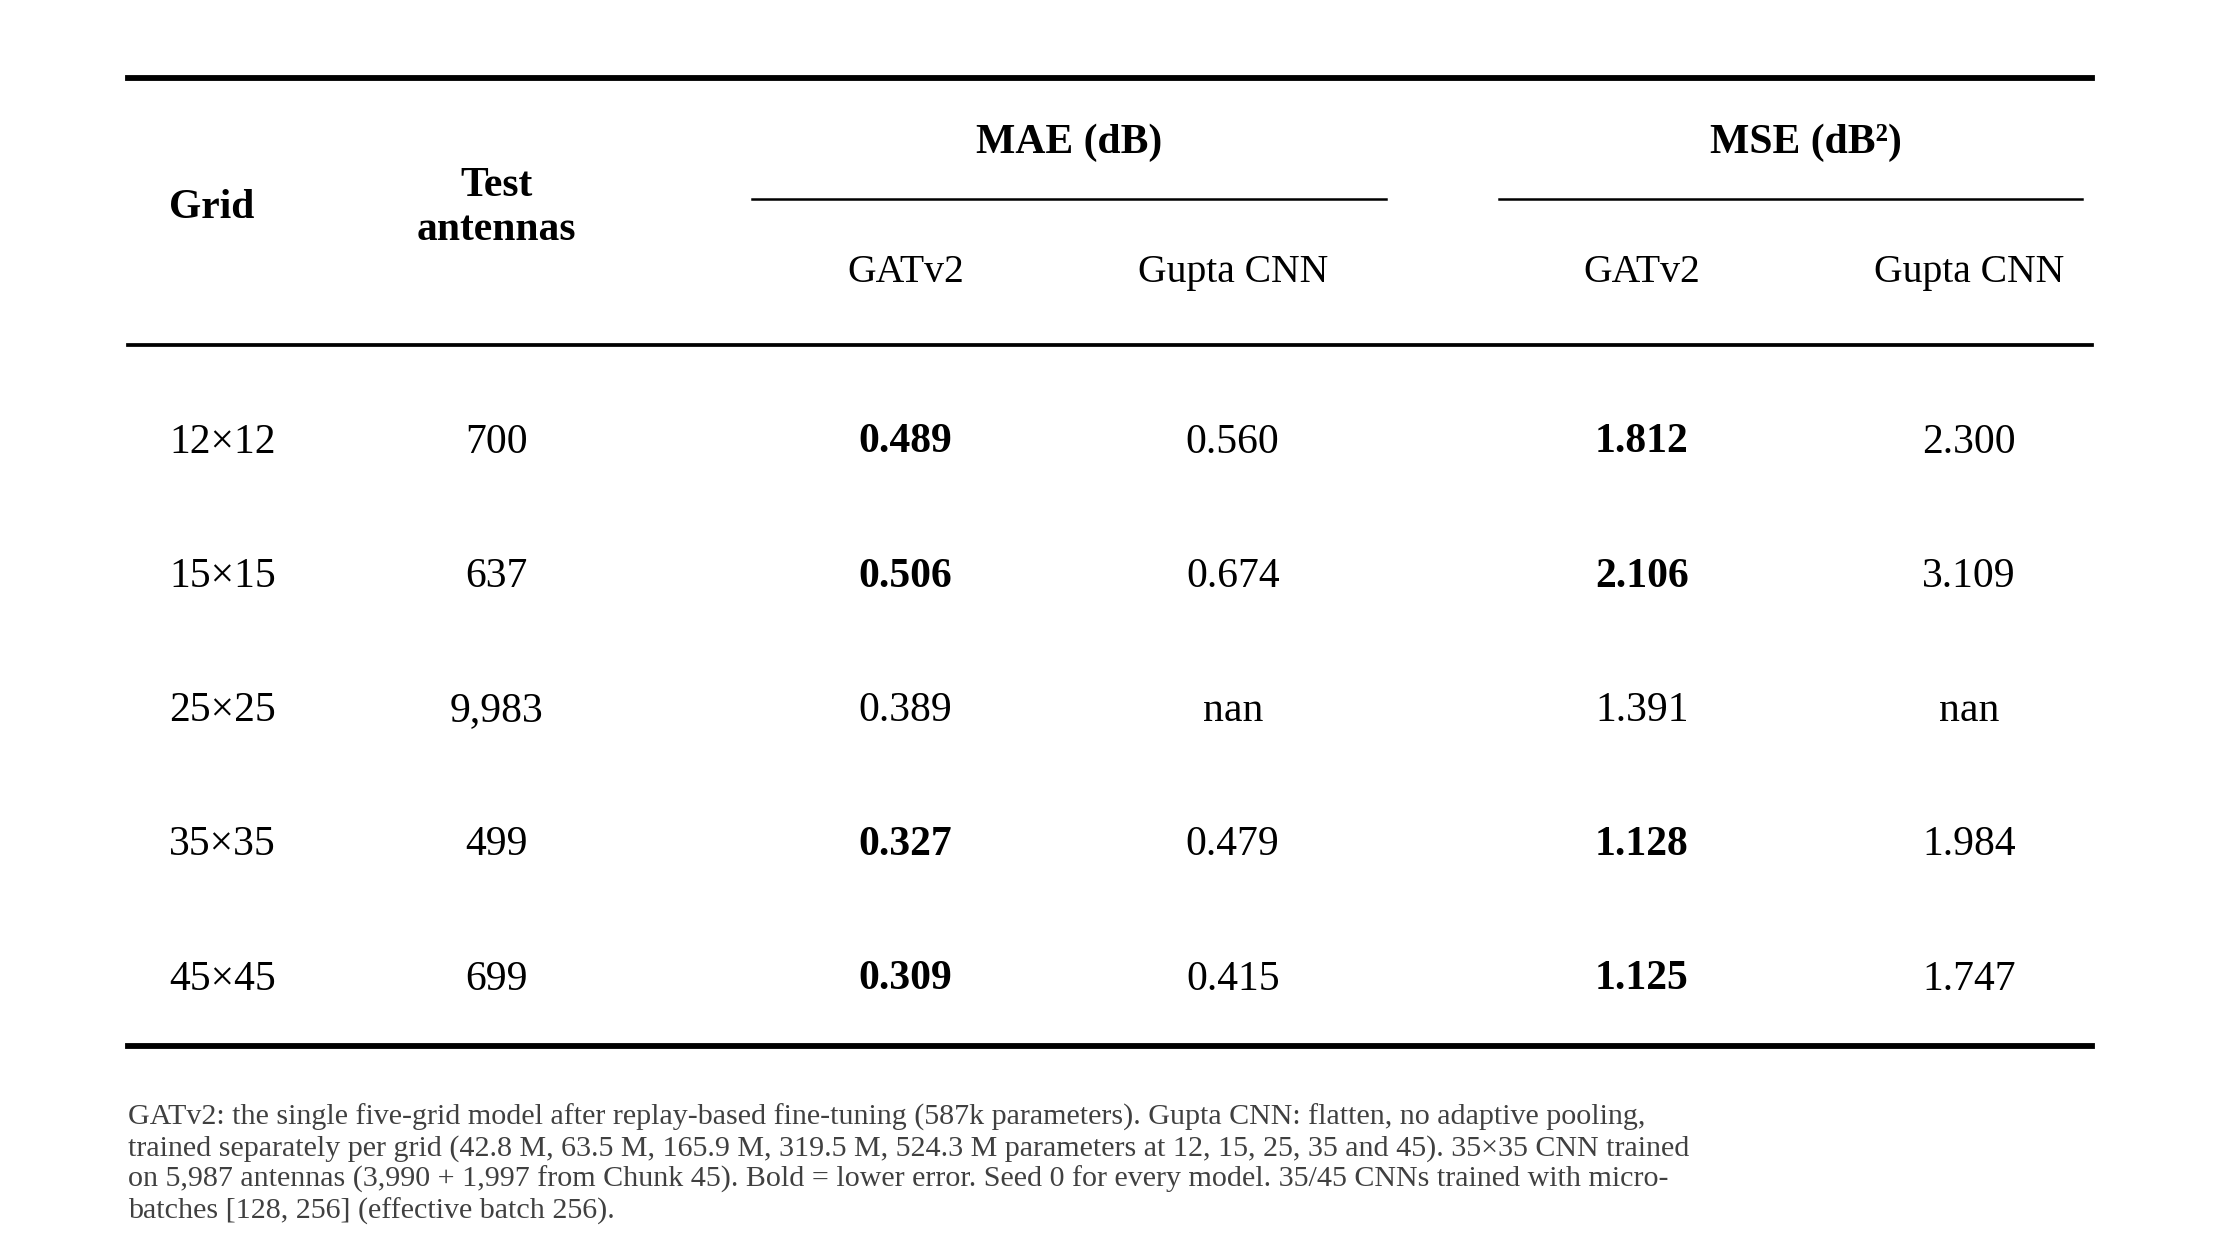

# Chunk 49 — Gupta CNN at 35×35 and 45×45; GATv2 vs Gupta CNN on every test set

One test touch; 95% stratified bootstrap intervals (1,000 resamples). Every earlier test number reproduced to within 0.005.

| grid | model | params | MSE (dB²) | MAE (dB) | R² | AUROC |
|---|---|---|---|---|---|---|
| 12×12 | ft15_from4_replay_p100_s0 | 587,129 | 1.812 [1.681, 1.962] | 0.489 [0.472, 0.506] | 0.662 [0.635, 0.687] | 0.799 |
| 12×12 | cnn12_p100_s0 | 42,771,473 | 2.300 [2.140, 2.476] | 0.560 [0.544, 0.578] | 0.571 [0.540, 0.600] | 0.763 |
| 15×15 | ft15_from4_replay_p100_s0 | 587,129 | 2.106 [1.948, 2.291] | 0.506 [0.488, 0.527] | 0.693 [0.663, 0.722] | 0.826 |
| 15×15 | cnn15_p100_s0 | 63,507,473 | 3.109 [2.890, 3.369] | 0.674 [0.652, 0.699] | 0.547 [0.506, 0.582] | 0.806 |
| 25×25 | ft15_from4_replay_p100_s0 | 587,129 | 1.391 [1.356, 1.427] | 0.389 [0.384, 0.394] | 0.834 [0.829, 0.839] | 0.905 |
| 35×35 | ft15_from4_replay_p100_s0 | 587,129 | 1.128 [0.987, 1.280] | 0.327 [0.305, 0.351] | 0

In [15]:
# ── Table image (Times-compatible serif) and report ──
!apt-get -qq install -y fonts-liberation > /dev/null 2>&1
from matplotlib import font_manager
for f in glob.glob('/usr/share/fonts/truetype/liberation/*.ttf'):
    font_manager.fontManager.addfont(f)
FONT = next((f for f in ('Times New Roman', 'Liberation Serif', 'DejaVu Serif') if any(f == x.name for x in font_manager.fontManager.ttflist)), 'serif')
plt.rcParams.update({'font.family': 'serif', 'font.serif': [FONT], 'mathtext.fontset': 'stix', 'pdf.fonttype': 42})
fig = plt.figure(figsize=(7.2, 3.55), dpi=300); ax = fig.add_axes([0, 0, 1, 1]); ax.axis('off')
X = [0.04, 0.20, 0.40, 0.56, 0.76, 0.92]; top = 0.93
ax.text(X[0], top - .06, 'Grid', ha='left', va='center', fontsize=10, fontweight='bold')
ax.text(X[1], top - .06, 'Test\nantennas', ha='center', va='center', fontsize=10, fontweight='bold')
ax.text((X[2] + X[3]) / 2, top - .02, 'MAE (dB)', ha='center', va='center', fontsize=10, fontweight='bold')
ax.text((X[4] + X[5]) / 2, top - .02, 'MSE (dB²)', ha='center', va='center', fontsize=10, fontweight='bold')
for x, l in zip(X[2:], ['GATv2', 'Gupta CNN', 'GATv2', 'Gupta CNN']):
    ax.text(x, top - .10, l, ha='center', va='center', fontsize=9.5)
ax.plot([.02, .98], [top + .02] * 2, lw=1.4, color='k')
ax.plot([X[2] - .075, X[3] + .075], [top - .055] * 2, lw=.6, color='k'); ax.plot([X[4] - .07, .975], [top - .055] * 2, lw=.6, color='k')
ax.plot([.02, .98], [top - .145] * 2, lw=.9, color='k')
y, dy = top - .205, .083
for r in SUM.itertuples():
    ax.text(X[0], y, r.grid.replace('x', '×'), ha='left', va='center', fontsize=10)
    ax.text(X[1], y, f'{r.n_test:,}', ha='center', va='center', fontsize=10)
    for xg, xc, a, b in ((X[2], X[3], r.gatv2_mae, r.cnn_mae), (X[4], X[5], r.gatv2_mse, r.cnn_mse)):
        ax.text(xg, y, f'{a:.3f}', ha='center', va='center', fontsize=10, fontweight='bold' if a < b else 'normal')
        ax.text(xc, y, f'{b:.3f}', ha='center', va='center', fontsize=10, fontweight='bold' if b < a else 'normal')
    y -= dy
ax.plot([.02, .98], [y + dy / 2] * 2, lw=1.4, color='k')
mb = sorted(set(RUNS_DF[RUNS_DF.run_id.isin([rid(N, 0) for N in GRIDS_NEW])].micro_batch))
note = ('GATv2: the single five-grid model after replay-based fine-tuning (587k parameters). Gupta CNN: flatten, no adaptive pooling, '
        'trained separately per grid (' + ', '.join(f'{expected_cnn_params(N) / 1e6:.1f} M' for N in GRIDS_ALL) + ' parameters at 12, 15, 25, 35 '
        'and 45). 35×35 CNN trained on 5,987 antennas (3,990 + 1,997 from Chunk 45). '
        + ('35×35 GATv2: Chunk 45 model trained on the same 5,987. ' if TABLE_GATV2_AT_35 == 'chunk45' else '')
        + 'Bold = lower error. Seed 0 for every model.' + ('' if mb == [256] else f' 35/45 CNNs trained with micro-batches {mb} (effective batch 256).'))
ax.text(.02, y + dy / 2 - .035, '\n'.join(textwrap.wrap(note, 128)), ha='left', va='top', fontsize=7.2, color='0.25')
for ext in ('png', 'pdf'):
    fig.savefig(OUT(f'ch49_table_gatv2_vs_gupta_cnn.{ext}'), dpi=600 if ext == 'png' else None, bbox_inches='tight', pad_inches=.05, facecolor='white')
plt.show(); plt.close(fig)

def fmt(mid, N, k):
    v = get(mid, N, k); return f'{v.estimate:.3f}' if np.isnan(v.lo) else f'{v.estimate:.3f} [{v.lo:.3f}, {v.hi:.3f}]'
L = ['# Chunk 49 — Gupta CNN at 35×35 and 45×45; GATv2 vs Gupta CNN on every test set', '',
     'One test touch; 95% stratified bootstrap intervals (1,000 resamples). Every earlier test number reproduced to within 0.005.', '',
     '| grid | model | params | MSE (dB²) | MAE (dB) | R² | AUROC |', '|---|---|---|---|---|---|---|']
for N in GRIDS_ALL:
    for mid in [GNN_ID] + ([GNN45_ID] if N == 35 else []) + sorted(set(MET[(MET.grid == N) & (MET.family == 'Gupta CNN')].model_id)):
        p = 587_129 if mid == GNN_ID else expected_cnn_params(N)
        L.append(f'| {N}×{N} | {mid} | {p:,} | {fmt(mid, N, "mse_db2")} | {fmt(mid, N, "mae_db")} | {fmt(mid, N, "r2")} | {fmt(mid, N, "auroc")} |')
L += ['', '## Paired: GATv2 − Gupta CNN (seed 0), same test antennas', PAIR.round(4).to_markdown(index=False), '',
      '## Chunk 49 runs', RUNS_DF.drop(columns=['checkpoint_sha256'], errors='ignore').round(4).to_markdown(index=False)]
open(OUT('ch49_report.md'), 'w').write('\n'.join(L) + '\n'); print('\n'.join(L))

## 12. Guards
**What it checks:**
- one test touch
- the seed-0 CNNs at 35/45 exist, with the expected parameter counts
- the 35×35 CNNs trained on 5,987 antennas (with the Chunk 45 extras) and the 45×45 CNNs on 5,587
- every Chunk 49 checkpoint matches its recorded SHA-256
- no run was stopped by its epoch cap
- input files unchanged, and no earlier file modified
- every output named `ch49_*`

In [16]:
# ── Guards ──
fails = []
def guard(ok, msg):
    print(f"  [{'PASS' if ok else 'FAIL'}] {msg}")
    if not ok: fails.append(msg)
R2 = pd.read_csv(RUNS)
guard(TEST_TOUCHES == 1, 'TEST touched exactly once')
guard({rid(N, 0) for N in GRIDS_NEW} <= set(R2.run_id), 'seed-0 CNNs trained at 35x35 and 45x45')
guard(all(r.n_params == expected_cnn_params(r.grid) for r in R2.itertuples()), 'parameter counts 319,507,473 (35) and 524,307,473 (45)')
guard(all(r.n_train == (5987 if r.grid == 35 else 5587) for r in R2.itertuples()), '35x35 CNNs trained on 5,987 antennas (3,990 + 1,997 Chunk 45); 45x45 on 5,587')
guard(all(sha(p) == h for p, h in zip(R2.checkpoint, R2.checkpoint_sha256)), 'every ch49 checkpoint matches its recorded SHA-256')
guard(not R2.budget_limited.any(), 'no run stopped by its epoch cap' if not R2.budget_limited.any() else
      f'BUDGET-LIMITED runs: {list(R2[R2.budget_limited].run_id)}')
guard(all(sha(p) == h for p, h in READ_SHA.items() if not Path(p).name.startswith('ch49_')), f'input files unchanged ({len(READ_SHA)})')
guard(all(os.path.getmtime(p) == t for p, t in PRIOR.items() if os.path.exists(p)), f'no earlier file modified ({len(PRIOR)})')
guard(all(Path(p).name.startswith('ch49_') for p in glob.glob(f'{ART}/ch49_*') + glob.glob(f'{CKPT}/ch49_*')), 'all outputs ch49_*')
if (R2.micro_batch < 256).any():
    print(f'  [NOTE] runs with micro-batches below 256 (BatchNorm sees micro-batch statistics): {list(R2[R2.micro_batch < 256].run_id)}')
assert not fails, fails
print('ALL GUARDS PASSED')

  [PASS] TEST touched exactly once
  [PASS] seed-0 CNNs trained at 35x35 and 45x45
  [PASS] parameter counts 319,507,473 (35) and 524,307,473 (45)
  [PASS] 35x35 CNNs trained on 5,987 antennas (3,990 + 1,997 Chunk 45); 45x45 on 5,587
  [PASS] every ch49 checkpoint matches its recorded SHA-256
  [PASS] no run stopped by its epoch cap
  [PASS] input files unchanged (33)
  [PASS] no earlier file modified (259)
  [PASS] all outputs ch49_*
  [NOTE] runs with micro-batches below 256 (BatchNorm sees micro-batch statistics): ['cnn45_p100_s0']
ALL GUARDS PASSED
